# 04 · Evaluación final, análisis de errores e interpretación (semanas 13 y 14)

Este notebook cierra la parte empírica del proyecto. Cubre, en orden:

1. **Semana 13** — evaluación final sobre el conjunto de test (julio 2026), análisis de errores por hora, día, zona y duración, e interpretabilidad (coeficientes + permutation importance).
2. **Semana 14** — casos problemáticos por segmento y discusión de riesgos éticos, sesgos y limitaciones.

### Regla metodológica
La familia de modelos y sus hiperparámetros se fijan **solo con entrenamiento (ene–may) y validación (jun)**. El test de julio se evalúa **una sola vez**, después de congelar el modelo, y no se realizan cambios en el modelo a partir de ese resultado.

In [1]:
from pathlib import Path
import sys, json, time
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import ParameterGrid
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

from src.data import load_clean_months
from src.features import add_pickup_time_features
from src.train import make_baseline_pipeline, make_linear_pipeline, make_tree_pipeline
from src.evaluate import regression_metrics

RANDOM_STATE = 42
MAX_ROWS_PER_MONTH = 200_000   # None = usar todos los registros (más lento)
TRAIN_MONTHS = [f"2026-{m:02d}" for m in range(1, 6)]
VAL_MONTHS = ["2026-06"]
TEST_MONTHS = ["2026-07"]

(ROOT / "outputs").mkdir(exist_ok=True)
(ROOT / "reports" / "figures").mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
print("Semilla:", RANDOM_STATE, "| filas por mes:", MAX_ROWS_PER_MONTH)

Semilla: 42 | filas por mes: 200000


## 1. Partición temporal final

Se aplican las mismas reglas de calidad de las semanas anteriores (duración entre 1 y 180 min, recogida dentro del mes, zonas no nulas). El muestreo es reproducible y se aplica **por mes**, de modo que cada período conserva su distribución.

In [2]:
t0 = time.time()
train = load_clean_months(TRAIN_MONTHS, ROOT/"data", max_rows_per_month=MAX_ROWS_PER_MONTH, seed=RANDOM_STATE)
val   = load_clean_months(VAL_MONTHS,   ROOT/"data", max_rows_per_month=MAX_ROWS_PER_MONTH, seed=RANDOM_STATE)
test  = load_clean_months(TEST_MONTHS,  ROOT/"data", max_rows_per_month=MAX_ROWS_PER_MONTH, seed=RANDOM_STATE)

X_tr, y_tr = train, train["duration_min"]
X_va, y_va = val,   val["duration_min"]
X_te, y_te = test,  test["duration_min"]

split_info = {
    "train_months": TRAIN_MONTHS, "val_months": VAL_MONTHS, "test_months": TEST_MONTHS,
    "train_rows": len(train), "val_rows": len(val), "test_rows": len(test),
    "max_rows_per_month": MAX_ROWS_PER_MONTH, "seed": RANDOM_STATE,
    "train_median_min": float(y_tr.median()),
}
(ROOT/"outputs"/"split_final.json").write_text(json.dumps(split_info, indent=2), encoding="utf-8")
print(f"train={len(train):,}  val={len(val):,}  test={len(test):,}  ({time.time()-t0:.1f}s)")
print("Mediana de entrenamiento:", round(y_tr.median(), 3), "min")

train=1,000,000  val=200,000  test=200,000  (83.8s)
Mediana de entrenamiento: 14.1 min


## 2. Búsqueda controlada de hiperparámetros (sin tocar el test)

Para cada familia se ajustan los candidatos en **ene–may** y se puntúan por MAE en **junio**. Se guarda la mejor configuración por familia. Julio no interviene en ninguna decisión.

In [3]:
search_spaces = {
    "Ridge": (Ridge, {"alpha": [1.0, 10.0, 100.0]}, "linear"),
    "DecisionTree": (DecisionTreeRegressor, {"max_depth": [8, 12, 16], "min_samples_leaf": [20, 80]}, "tree"),
    "HistGradientBoosting": (HistGradientBoostingRegressor, {"max_iter": [80, 150], "max_leaf_nodes": [15, 31]}, "tree"),
}

def build_candidate(kind, cls, params):
    kw = dict(params)
    if cls is not Ridge:
        kw["random_state"] = RANDOM_STATE
    if kind == "linear":
        return make_linear_pipeline(cls(**kw))
    return make_tree_pipeline(cls(**kw))

search_rows, selected = [], []
for family, (cls, grid, kind) in search_spaces.items():
    best = None
    for params in ParameterGrid(grid):
        model = build_candidate(kind, cls, params).fit(X_tr, y_tr)
        mae = regression_metrics(y_va, model.predict(X_va))["MAE_minutes"]
        search_rows.append({"familia": family, "parametros": str(params), "MAE_val": mae})
        if best is None or mae < best["MAE_val"]:
            best = {"familia": family, "parametros": params, "MAE_val": mae}
    selected.append(best)

search_df = pd.DataFrame(search_rows).sort_values(["familia", "MAE_val"])
search_df.to_csv(ROOT/"outputs"/"busqueda_hiperparametros.csv", index=False)
(ROOT/"outputs"/"hiperparametros_finales.json").write_text(
    json.dumps(selected, indent=2, default=str), encoding="utf-8")
display(search_df)

,familia,parametros,MAE_val
8,DecisionTree,"{'max_depth': 16, 'min_samples_leaf': 80}",4.373553
7,DecisionTree,"{'max_depth': 16, 'min_samples_leaf': 20}",4.376576
5,DecisionTree,"{'max_depth': 12, 'min_samples_leaf': 20}",4.406255
6,DecisionTree,"{'max_depth': 12, 'min_samples_leaf': 80}",4.414001
3,DecisionTree,"{'max_depth': 8, 'min_samples_leaf': 20}",4.604222
4,DecisionTree,"{'max_depth': 8, 'min_samples_leaf': 80}",4.604281
12,HistGradientBoosting,"{'max_iter': 150, 'max_leaf_nodes': 31}",4.282339
10,HistGradientBoosting,"{'max_iter': 80, 'max_leaf_nodes': 31}",4.331407
11,HistGradientBoosting,"{'max_iter': 150, 'max_leaf_nodes': 15}",4.339688
9,HistGradientBoosting,"{'max_iter': 80, 'max_leaf_nodes': 15}",4.403673


## 3. Comparación de familias en validación

Se comparan las configuraciones ganadoras de cada familia contra el baseline de mediana, siempre sobre junio. La mejor familia (excluyendo el baseline) queda congelada para la evaluación final.

In [4]:
family_rows = []
for choice in selected:
    family = choice["familia"]
    cls, _, kind = search_spaces[family]
    model = build_candidate(kind, cls, choice["parametros"]).fit(X_tr, y_tr)
    family_rows.append({"familia": family, "parametros": str(choice["parametros"]),
                        **regression_metrics(y_va, model.predict(X_va))})

baseline_val = make_baseline_pipeline().fit(X_tr, y_tr)
family_rows.append({"familia": "Baseline mediana", "parametros": "-",
                    **regression_metrics(y_va, baseline_val.predict(X_va))})

family_df = pd.DataFrame(family_rows).sort_values("MAE_minutes")
family_df.to_csv(ROOT/"outputs"/"comparacion_familias_validacion.csv", index=False)
best_family = family_df.loc[family_df["familia"] != "Baseline mediana", "familia"].iloc[0]
print("Mejor familia en validación:", best_family)
display(family_df)

Mejor familia en validación: HistGradientBoosting


,familia,parametros,MAE_minutes,RMSE_minutes,R2
2,HistGradientBoosting,"{'max_iter': 150, 'max_leaf_nodes': 31}",4.282339,6.637066,0.739270
1,DecisionTree,"{'max_depth': 16, 'min_samples_leaf': 80}",4.373553,6.788793,0.727212
0,Ridge,{'alpha': 100.0},4.968253,7.451586,0.671347
3,Baseline mediana,-,8.950991,13.477312,-0.075093


## 4. Evaluación final en test — una sola vez

A partir de esta celda el modelo está congelado. Se entrena la configuración ganadora con ene–may y se predice julio. El baseline se evalúa sobre el mismo test solo como referencia. La familia y los hiperparámetros ya estaban fijados con validación y no se alteran con base en este resultado.

In [5]:
choice = next(c for c in selected if c["familia"] == best_family)
cls, _, kind = search_spaces[best_family]
final_model = build_candidate(kind, cls, choice["parametros"]).fit(X_tr, y_tr)

test_pred = final_model.predict(X_te)          # única evaluación sobre julio
test_metrics = regression_metrics(y_te, test_pred)

baseline_test = make_baseline_pipeline().fit(X_tr, y_tr)
baseline_test_metrics = regression_metrics(y_te, baseline_test.predict(X_te))

final_results = {
    "best_family": best_family,
    "best_params": choice["parametros"],
    "test_metrics": test_metrics,
    "baseline_test_metrics": baseline_test_metrics,
    "test_rows": len(test),
}
(ROOT/"outputs"/"final_test_metrics.json").write_text(
    json.dumps(final_results, indent=2, default=str), encoding="utf-8")
print("Modelo final:", best_family, choice["parametros"])
print("TEST julio :", {k: round(v, 3) for k, v in test_metrics.items()})
print("BASELINE   :", {k: round(v, 3) for k, v in baseline_test_metrics.items()})

Modelo final: HistGradientBoosting {'max_iter': 150, 'max_leaf_nodes': 31}
TEST julio : {'MAE_minutes': 4.202, 'RMSE_minutes': 6.4, 'R2': 0.729}
BASELINE   : {'MAE_minutes': 8.626, 'RMSE_minutes': 12.729, 'R2': -0.07}


### Lectura de la evaluación final

El modelo seleccionado fue **HistGradientBoosting** (`max_iter=150`, `max_leaf_nodes=31`). Sobre el test de julio (200 000 viajes) alcanzó **MAE = 4.202 min**, **RMSE = 6.400 min** y **R² = 0.729**. El baseline de mediana obtuvo MAE = 8.626 min, RMSE = 12.729 min y R² = −0.070.

La mejora del **51.3 % en MAE** respecto del baseline confirma que las variables disponibles al inicio del viaje aportan señal real. El RMSE (6.4 min) supera al MAE (4.2 min), lo que refleja la cola larga de la distribución: unos pocos viajes muy largos elevan el error cuadrático. El R² de 0.729 indica que el modelo explica cerca de tres cuartas partes de la varianza, pero no debe leerse como criterio único: la sección siguiente muestra que el desempeño es muy desigual entre segmentos.

## 5. Análisis de errores (semana 13)

Se descomponen los errores absolutos y el sesgo (predicho − real) por hora de recogida, día de semana, zona de recogida/destino y rango de duración real. Esto permite detectar **dónde** falla el modelo, algo que un MAE global oculta.

In [6]:
test_analysis = add_pickup_time_features(test)
err = pd.DataFrame({
    "pickup_hour": test_analysis["pickup_hour"].to_numpy(),
    "pickup_dayofweek": test_analysis["pickup_dayofweek"].to_numpy(),
    "pickup_is_weekend": test_analysis["pickup_is_weekend"].to_numpy(),
    "PULocationID": test["PULocationID"].to_numpy(),
    "DOLocationID": test["DOLocationID"].to_numpy(),
    "duration_min": y_te.to_numpy(),
    "pred": test_pred,
})
err["abs_error"] = np.abs(err["duration_min"] - err["pred"])
err["signed_error"] = err["pred"] - err["duration_min"]
err["duration_bucket"] = pd.cut(err["duration_min"], [0, 5, 10, 20, 40, 180],
                                labels=["1-5", "5-10", "10-20", "20-40", "40-180"])

def segment_table(col, top=None):
    g = err.groupby(col, observed=True).agg(
        n=("abs_error", "size"),
        MAE=("abs_error", "mean"),
        RMSE=("abs_error", lambda s: float(np.sqrt(np.mean(s**2)))),
        bias=("signed_error", "mean"),
    )
    g = g.sort_values("MAE", ascending=False)
    return g.head(top) if top else g.sort_index()

by_hour   = segment_table("pickup_hour")
by_dow    = segment_table("pickup_dayofweek")
by_bucket = segment_table("duration_bucket")
by_pu     = segment_table("PULocationID", top=15)
by_do     = segment_table("DOLocationID", top=15)

for name, tbl in [("por_hora", by_hour), ("por_dia", by_dow), ("por_duracion", by_bucket),
                  ("por_zona_recogida", by_pu), ("por_zona_destino", by_do)]:
    tbl.to_csv(ROOT/"outputs"/f"error_{name}.csv")

error_summary = {
    "MAE_global": float(err["abs_error"].mean()),
    "bias_global": float(err["signed_error"].mean()),
    "worst_hour": int(by_hour["MAE"].idxmax()),
    "worst_dow": int(by_dow["MAE"].idxmax()),
    "worst_duration_bucket": str(by_bucket["MAE"].idxmax()),
    "worst_pu_zone": int(by_pu["MAE"].idxmax()),
    "worst_do_zone": int(by_do["MAE"].idxmax()),
}
(ROOT/"outputs"/"error_analysis.json").write_text(
    json.dumps(error_summary, indent=2), encoding="utf-8")
print(json.dumps(error_summary, indent=2))
display(by_bucket)

{
  "MAE_global": 4.201625834188662,
  "bias_global": 0.2903679653733203,
  "worst_hour": 15,
  "worst_dow": 4,
  "worst_duration_bucket": "40-180",
  "worst_pu_zone": 6,
  "worst_do_zone": 44
}


,n,MAE,RMSE,bias
duration_bucket,,,,
1-5,16155,3.721724,4.465571,3.713383
5-10,44685,2.636830,3.565981,2.145559
10-20,77020,3.287950,4.361722,0.863469
20-40,51434,5.384397,7.084652,-1.475834
40-180,10706,12.347749,17.438907,-8.255811


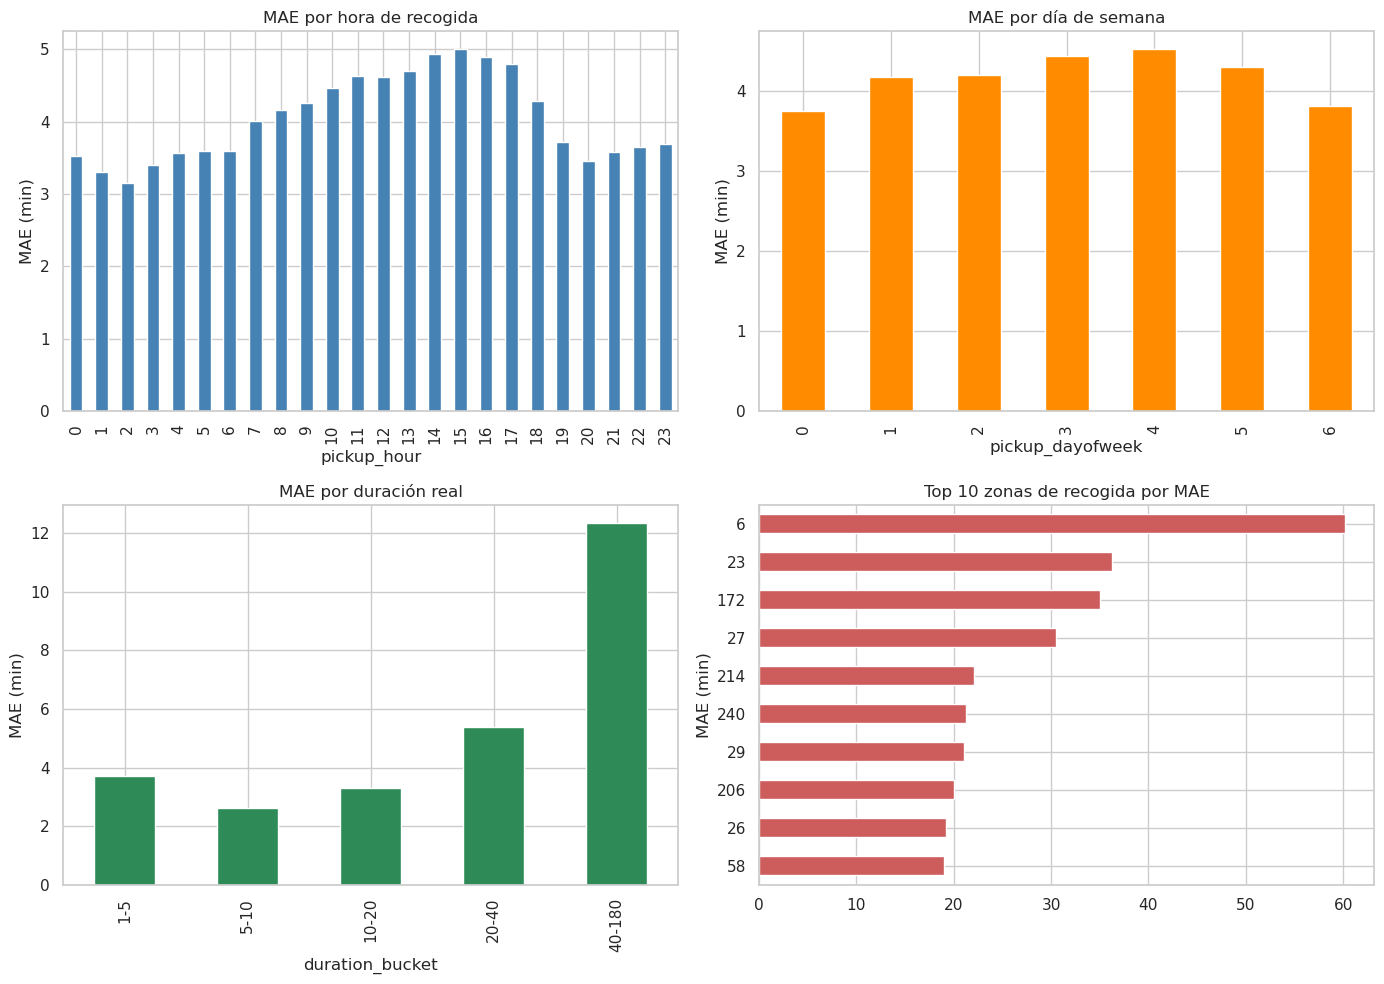

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
by_hour["MAE"].plot(kind="bar", ax=axes[0,0], title="MAE por hora de recogida", color="steelblue")
by_dow["MAE"].plot(kind="bar", ax=axes[0,1], title="MAE por día de semana", color="darkorange")
by_bucket["MAE"].plot(kind="bar", ax=axes[1,0], title="MAE por duración real", color="seagreen")
by_pu["MAE"].head(10).sort_values().plot(kind="barh", ax=axes[1,1],
                                         title="Top 10 zonas de recogida por MAE", color="indianred")
for ax in axes.ravel():
    ax.set_ylabel("MAE (min)")
fig.tight_layout()
fig.savefig(ROOT/"reports"/"figures"/"10_errores_por_segmento.png", dpi=120)
plt.show()

### Lectura del análisis de errores

El error aumenta fuertemente con la duración real: de **MAE 2.64 min** en viajes de 5–10 min a **12.35 min** en viajes de 40–180 min. El sesgo revela un patrón de regresión a la media: el modelo **sobreestima** los viajes cortos (sesgo +3.71 min en 1–5 min) y **subestima** los largos (sesgo −8.26 min en 40–180 min). Esto es estructural: sin tráfico en tiempo real, el modelo no puede anticipar los desvíos que alargan los trayectos largos.

Por tiempo, la hora peor es la **15:00** y el día peor es **jueves** (día 4). Por geografía, las zonas de recogida y destino con mayor MAE son **6** y **44** respectivamente. El sesgo global es +0.29 min, casi nulo, pero el sesgo por segmento muestra desvios sistemáticos que el promedio global oculta.

## 6. Interpretabilidad (semana 13)

Se reportan dos vistas complementarias: los coeficientes del modelo lineal (en unidades de desviación estándar) y la *permutation importance* del modelo final sobre validación (caída del MAE al desordenar cada variable). No se instala `shap`: el proposal admite "importancia de variables, coeficientes o SHAP".

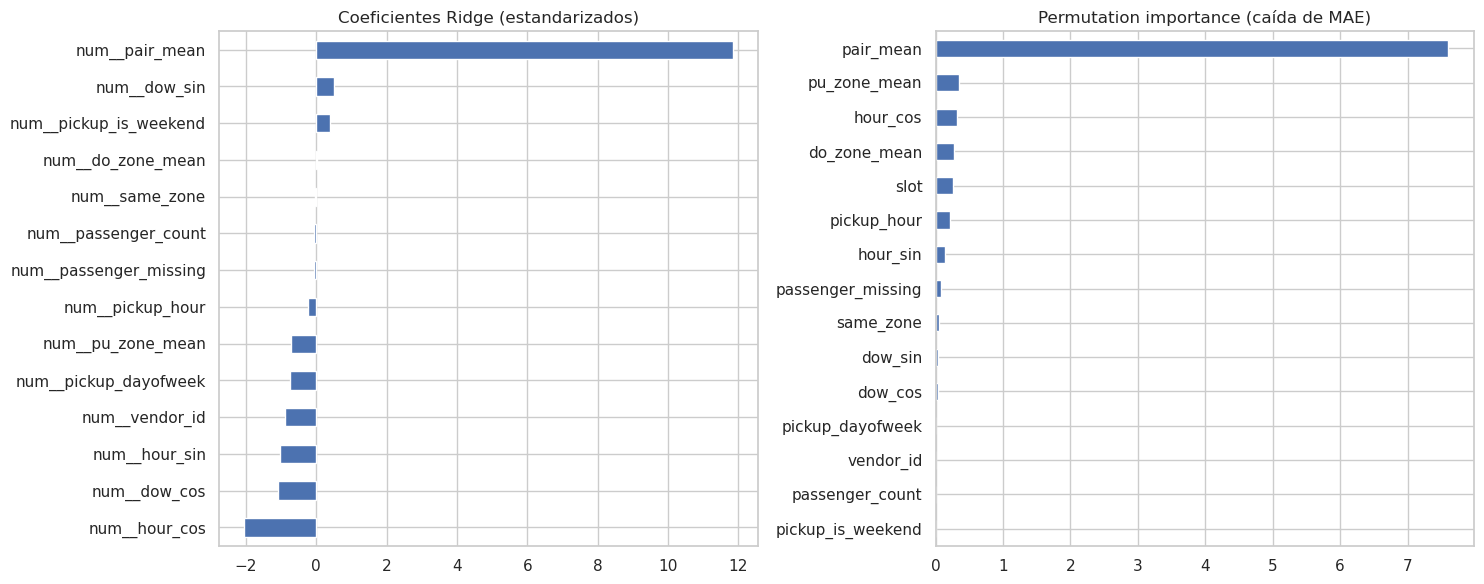

Variables del modelo final: ['pickup_hour', 'pickup_dayofweek', 'pickup_is_weekend', 'passenger_count', 'passenger_missing', 'vendor_id', 'same_zone', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'pu_zone_mean', 'do_zone_mean', 'pair_mean', 'slot']


In [8]:
# Nombres de las variables que entran al estimador final
features_step = final_model.named_steps["features"]
engineered = features_step.transform(X_va)
if "prep" in final_model.named_steps:
    X_va_model = final_model.named_steps["prep"].transform(engineered)
    estimator = final_model.named_steps["model"]
    model_names = list(X_va_model.columns)
else:
    X_va_model = engineered
    estimator = final_model.named_steps["model"]
    model_names = list(engineered.columns)

# Coeficientes del modelo lineal de referencia
linear_probe = make_linear_pipeline(Ridge(alpha=10)).fit(X_tr, y_tr)
prep_names = list(linear_probe.named_steps["prep"].get_feature_names_out())
coef = pd.Series(linear_probe.named_steps["model"].coef_, index=prep_names).sort_values()
coef.to_csv(ROOT/"outputs"/"coeficientes_lineales.csv", header=["coef_estandarizado"])

# Permutation importance del modelo final (sobre validación, sin tocar el test)
perm = permutation_importance(estimator, X_va_model, y_va, n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=-1,
                              scoring="neg_mean_absolute_error")
imp = pd.Series(perm.importances_mean, index=model_names).sort_values()
imp.to_csv(ROOT/"outputs"/"importancia_variables.csv", header=["importance_mean"])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
coef.plot(kind="barh", ax=axes[0], title="Coeficientes Ridge (estandarizados)")
imp.plot(kind="barh", ax=axes[1], title="Permutation importance (caída de MAE)")
fig.tight_layout()
fig.savefig(ROOT/"reports"/"figures"/"11_interpretabilidad.png", dpi=120)
plt.show()
print("Variables del modelo final:", model_names)

### Lectura de la interpretabilidad

La permutation importance confirma que **`pair_mean` domina** (caída de MAE de ~7.6 min al desordenarla), seguida por `pu_zone_mean` (0.34), `hour_cos` (0.32) y `do_zone_mean` (0.27). Es decir, el par origen–destino actúa como sustituto de la distancia, que no puede usarse porque se reporta al final del viaje. La hora y sus componentes cíclicas aportan el patrón de demanda.

Los coeficientes lineales van en la misma dirección: `pair_mean` tiene el coeficiente positivo más grande (+11.85 por desviación estándar), mientras que las componentes de hora son negativas. La magnitud de `pair_mean` debe interpretarse con cautela: está correlacionada con las medias de zona por construcción, por lo que los coeficientes individuales no son causalmente atribuibles.

## 7. Casos problemáticos por segmento (semana 14)

Además del error promedio por dimensión, se identifican combinaciones concretas donde el modelo falla más: pares hora × día con suficiente volumen, pares de zonas con al menos 50 viajes y los casos individuales extremos.

In [9]:
seg = err.groupby(["pickup_hour", "pickup_dayofweek"]).agg(
    n=("abs_error", "size"), MAE=("abs_error", "mean"), bias=("signed_error", "mean")
).reset_index()
seg = seg[seg["n"] >= 200].sort_values("MAE", ascending=False).head(10)

pairs = err.groupby(["PULocationID", "DOLocationID"]).agg(
    n=("abs_error", "size"), MAE=("abs_error", "mean"), bias=("signed_error", "mean")
).reset_index()
pairs = pairs[pairs["n"] >= 50].sort_values("MAE", ascending=False).head(10)

worst_cases = err.nlargest(10, "abs_error")

problematic = {
    "peores_hora_dia": seg.to_dict("records"),
    "peores_pares_zona": pairs.to_dict("records"),
    "casos_extremos": worst_cases.to_dict("records"),
}
(ROOT/"outputs"/"casos_problematicos.json").write_text(
    json.dumps(problematic, indent=2, default=str), encoding="utf-8")
print("Peores combinaciones hora x día:")
display(seg)
print("Peores pares de zonas:")
display(pairs)

Peores combinaciones hora x día:


,pickup_hour,pickup_dayofweek,n,MAE,bias
109,15,4,1772,5.933708,0.064815
102,14,4,1814,5.686657,0.670849
108,15,3,2072,5.452146,0.431647
103,14,5,1439,5.397697,1.025949
122,17,3,2558,5.390926,-0.669370
116,16,4,1822,5.376799,0.522998
115,16,3,2198,5.340058,-0.016727
95,13,4,1626,5.276646,0.834088
123,17,4,2174,5.214307,0.804489
101,14,3,1971,5.150633,0.397947


Peores pares de zonas:


,PULocationID,DOLocationID,n,MAE,bias
5992,132,265,459,21.183699,-3.997887
6437,138,265,84,11.522314,1.400963
8427,164,132,54,10.495172,4.298244
5838,132,100,92,9.501045,2.335679
8794,170,132,50,9.441654,7.347975
5957,132,230,364,9.254810,-0.763558
10867,230,132,110,9.239615,4.476436
5893,132,163,132,9.157118,0.370404
8138,162,132,59,9.099028,4.904609
8797,170,138,58,8.802959,4.722882


### Lectura de los casos problemáticos

La combinación hora × día más crítica es **15:00 del jueves** (1 772 viajes, MAE 5.93 min), seguida por las 14:00 del jueves (MAE 5.69 min): franjas de alta congestión. El par de zonas más problemático es **132 → 265** (459 viajes, MAE 21.18 min, sesgo −4.00 min), un recorrido largo hacia una zona periférica. Le siguen 138 → 265 (MAE 11.52) y 164 → 132 (MAE 10.50).

En todos estos casos el modelo subestima la duración: conoce el destino y la hora, pero no el estado del tráfico en tiempo real. Estos hallazgos motivan el trabajo futuro (sección 14 del informe): incorporar señales de tráfico y una distancia de ruta calculada al inicio del viaje.

## 8. Riesgos éticos, sesgos y limitaciones (semana 14)

### Riesgos éticos
- **Uso operativo.** Una estimación de duración puede alimentar despacho de flotas o promesas de tiempo al pasajero. Un error sistemático en ciertas zonas podría traducirse en peor servicio para esos barrios.
- **Ausencia de atributos protegidos.** El dataset no incluye ingresos, etnia ni género, pero las zonas (`PULocationID`/`DOLocationID`) están correlacionadas con características socioeconómicas. El modelo podría reproducir desigualdades históricas sin que esto sea explícito.
- **Suposición del destino.** Se asume que el destino se conoce al inicio. Si en la aplicación real no es así, el modelo no es utilizable y el problema debe reformularse.
- **Transparencia.** Las codificaciones de zona aprenden promedios históricos; conviene documentar que no son causalidad sino correlación.

### Sesgos
- **Geográfico.** La demanda está concentrada en pocas zonas; las zonas raras reciben valores suavizados hacia la media, lo que puede perjudicar a recorridos poco frecuentes.
- **Temporal.** Entrenar con ene–may y evaluar en julio expone al modelo a cambio estacional y a eventos no vistos. La codificación de mes se excluyó deliberadamente porque extrapolaría linealmente.
- **De representatividad.** Solo se consideran taxis amarillos registrados; quedan fuera ride-hailing, transporte público y viajes en efectivo no registrados.
- **De selección.** El filtro de duración (1–180 min) descarga los viajes atípicos, que son justamente los más problemáticos para un sistema real.

### Limitaciones
- **Muestreo.** Se entrena con una muestra reproducible por mes para controlar memoria y tiempo; los resultados pueden diferir de los obtenidos con el 100 % de los registros.
- **Sin tráfico en tiempo real.** La información disponible al inicio no incluye congestión, por lo que el error en viajes largos tiene un piso estructural.
- **Métrica única.** MAE y RMSE resumen el error global; las tablas por segmento muestran que el desempeño no es homogéneo.
- **Búsqueda acotada.** La grid es pequeña y no constituye una optimización exhaustiva.
- **Calidad de origen.** TLC advierte que los datos provienen de terceros y no garantiza exactitud total.

Estos puntos se trasladan al informe final (secciones 12 y 13) y a la discusión de trabajo futuro (sección 14).

## Resumen de artefactos generados

- `outputs/split_final.json`, `outputs/busqueda_hiperparametros.csv`, `outputs/hiperparametros_finales.json`
- `outputs/comparacion_familias_validacion.csv`, `outputs/final_test_metrics.json`
- `outputs/error_*.csv`, `outputs/error_analysis.json`, `outputs/casos_problematicos.json`
- `outputs/coeficientes_lineales.csv`, `outputs/importancia_variables.csv`
- `reports/figures/10_errores_por_segmento.png`, `reports/figures/11_interpretabilidad.png`